# A KDD-Based Predictive Analytics System for Solar Power Generation Forecasting and Renewable Energy Planning

**Course:** Predictive Analytics  
**Environment:** Google Colab / Jupyter Notebook  
**Problem type:** Regression  
**Primary target:** Plant-level AC power output (`AC_POWER`)

## 1. Problem statement
Develop a predictive regression model to estimate solar power generation from historical generation and environmental sensor data. The project follows the KDD workflow: data selection, preprocessing, exploratory data analysis (EDA), transformation, feature selection, modelling, evaluation, and knowledge discovery.

Forecasting scope: this notebook predicts AC power for timestamps represented by contemporaneous weather measurements and time-based features. Because the dataset spans only about 34 days, results should be treated as a learning experiment rather than a reliable long-term operational forecast.

## 2. Dataset
Source: [Kaggle — Solar Power Generation Data by Anikannal](https://www.kaggle.com/datasets/anikannal/solar-power-generation-data)

The dataset contains four CSV files for two solar plants in India:
- `Plant_1_Generation_Data.csv`
- `Plant_1_Weather_Sensor_Data.csv`
- `Plant_2_Generation_Data.csv`
- `Plant_2_Weather_Sensor_Data.csv`

Generation data is collected at inverter level; weather data is collected at plant level. Common columns include:
- Generation: `DATE_TIME`, `PLANT_ID`, `SOURCE_KEY`, `DC_POWER`, `AC_POWER`, `DAILY_YIELD`, `TOTAL_YIELD`
- Weather: `DATE_TIME`, `PLANT_ID`, `SOURCE_KEY`, `AMBIENT_TEMPERATURE`, `MODULE_TEMPERATURE`, `IRRADIATION`

The notebook uses actual column names from the published dataset. It merges generation and weather by timestamp and plant, aggregates inverter output to plant level, and uses a chronological train/test split.

## Important modelling decision: avoid target leakage
For the primary environmental forecast, predictors exclude `DC_POWER`, `DAILY_YIELD`, and `TOTAL_YIELD` because they are direct generation-related variables that can make the task unrealistically easy. The target is summed `AC_POWER` at plant/timestamp level. Weather and time-derived features are used.

The original Kaggle dataset is not bundled here; download the four CSVs and upload them when prompted. Check the dataset's licence/terms before redistributing data.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Plant_1_Generation_Data.csv to Plant_1_Generation_Data.csv
Saving Plant_1_Weather_Sensor_Data.csv to Plant_1_Weather_Sensor_Data.csv
Saving Plant_2_Generation_Data.csv to Plant_2_Generation_Data.csv
Saving Plant_2_Weather_Sensor_Data.csv to Plant_2_Weather_Sensor_Data.csv


## 3. Import libraries

In [ ]:
import io, os, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme()
print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Data selection and upload
Upload the four CSV files from Kaggle. Filenames should include the plant number and data type.

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("Upload the four Kaggle CSV files and rerun this cell.")
    raw_files = {name: data for name, data in uploaded.items()}
except ImportError:
    # Local Jupyter: place the four CSVs in ./dataset/
    folder = "dataset"
    if not os.path.isdir(folder):
        raise FileNotFoundError("Place the four CSV files in a folder named 'dataset'.")
    raw_files = {}
    for name in os.listdir(folder):
        if name.lower().endswith(".csv"):
            with open(os.path.join(folder, name), "rb") as f:
                raw_files[name] = f.read()

print("Files provided:")
for name in raw_files:
    print(" -", name)

def find_file(plant_num, kind):
    # Handles names like Plant_1_Generation_Data.csv, Plant_1_Weather_Sensor_Data.csv.
    candidates = []
    for name in raw_files:
        low = name.lower().replace("-", "_").replace(" ", "_")
        if f"plant_{plant_num}" in low and kind in low:
            candidates.append(name)
    if not candidates:
        raise FileNotFoundError(f"Could not find Plant_{plant_num} file containing '{kind}'. Uploaded: {list(raw_files)}")
    return candidates[0]

generation_frames = []
weather_frames = []
for plant_num in (1, 2):
    gen_name = find_file(plant_num, "generation")
    weather_name = find_file(plant_num, "weather")
    gen = pd.read_csv(io.BytesIO(raw_files[gen_name]))
    weather = pd.read_csv(io.BytesIO(raw_files[weather_name]))
    gen.columns = gen.columns.str.strip()
    weather.columns = weather.columns.str.strip()
    gen["DATE_TIME"] = pd.to_datetime(gen["DATE_TIME"], dayfirst=True, errors="coerce")
    weather["DATE_TIME"] = pd.to_datetime(weather["DATE_TIME"], dayfirst=True, errors="coerce")
    gen["PLANT_ID"] = gen["PLANT_ID"].astype(str)
    weather["PLANT_ID"] = weather["PLANT_ID"].astype(str)
    generation_frames.append(gen)
    weather_frames.append(weather)
    print(f"Plant {plant_num}: generation {gen.shape}, weather {weather.shape}")

generation = pd.concat(generation_frames, ignore_index=True)
weather = pd.concat(weather_frames, ignore_index=True)

print("Combined generation shape:", generation.shape)
print("Combined weather shape:", weather.shape)
display(generation.head())
display(weather.head())

Saving Plant_1_Generation_Data.csv to Plant_1_Generation_Data (1).csv
Saving Plant_1_Weather_Sensor_Data.csv to Plant_1_Weather_Sensor_Data (1).csv
Saving Plant_2_Generation_Data.csv to Plant_2_Generation_Data (1).csv
Saving Plant_2_Weather_Sensor_Data.csv to Plant_2_Weather_Sensor_Data (1).csv
Files provided:
 - Plant_1_Generation_Data (1).csv
 - Plant_1_Weather_Sensor_Data (1).csv
 - Plant_2_Generation_Data (1).csv
 - Plant_2_Weather_Sensor_Data (1).csv
Plant 1: generation (68778, 7), weather (3182, 6)
Plant 2: generation (67698, 7), weather (3259, 6)
Combined generation shape: (136476, 7)
Combined weather shape: (6441, 6)


/tmp/ipykernel_1536/2900582244.py:43: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  weather["DATE_TIME"] = pd.to_datetime(weather["DATE_TIME"], dayfirst=True, errors="coerce")
/tmp/ipykernel_1536/2900582244.py:42: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  gen["DATE_TIME"] = pd.to_datetime(gen["DATE_TIME"], dayfirst=True, errors="coerce")
/tmp/ipykernel_1536/2900582244.py:43: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  weather["DATE_TIME"] = pd.to_datetime(weather["DATE_TIME"], dayfirst=True, errors="coerce")


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


## 5. Data preprocessing and integration
Clean timestamp/target records, aggregate inverter-level generation to plant-level timestamps, average weather readings at plant/timestamp level, then merge. This ensures the target and weather predictors share the same granularity.

In [ ]:
# Drop rows without usable timestamps.
generation = generation.dropna(subset=["DATE_TIME", "PLANT_ID", "AC_POWER"]).copy()
weather = weather.dropna(subset=["DATE_TIME", "PLANT_ID"]).copy()

# Coerce expected numeric fields safely.
for col in ["AC_POWER", "DC_POWER", "DAILY_YIELD", "TOTAL_YIELD"]:
    if col in generation.columns:
        generation[col] = pd.to_numeric(generation[col], errors="coerce")
for col in ["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]:
    if col in weather.columns:
        weather[col] = pd.to_numeric(weather[col], errors="coerce")

# Aggregate inverter records to plant and timestamp.
gen_agg = generation.groupby(["PLANT_ID", "DATE_TIME"], as_index=False).agg(
    AC_POWER=("AC_POWER", "sum"),
    DC_POWER=("DC_POWER", "sum"),
    INVERTER_COUNT=("SOURCE_KEY", "nunique")
)

# Sensor data is plant-level; average duplicate sensor rows if any.
weather_agg = weather.groupby(["PLANT_ID", "DATE_TIME"], as_index=False).agg(
    AMBIENT_TEMPERATURE=("AMBIENT_TEMPERATURE", "mean"),
    MODULE_TEMPERATURE=("MODULE_TEMPERATURE", "mean"),
    IRRADIATION=("IRRADIATION", "mean")
)

data = gen_agg.merge(
    weather_agg, on=["PLANT_ID", "DATE_TIME"], how="inner", validate="one_to_one"
)
data = data.sort_values(["PLANT_ID", "DATE_TIME"]).reset_index(drop=True)
data = data.drop_duplicates(subset=["PLANT_ID", "DATE_TIME"])

print("Integrated dataset shape:", data.shape)
print("Time range:", data["DATE_TIME"].min(), "to", data["DATE_TIME"].max())
print("Missing values:")
display(data.isna().sum().rename("missing_count").to_frame())
display(data.head())

Integrated dataset shape: (6416, 8)
Time range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Missing values:


,missing_count
PLANT_ID,0
DATE_TIME,0
AC_POWER,0
DC_POWER,0
INVERTER_COUNT,0
AMBIENT_TEMPERATURE,0
MODULE_TEMPERATURE,0
IRRADIATION,0


,PLANT_ID,DATE_TIME,AC_POWER,DC_POWER,INVERTER_COUNT,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,4135001,2020-05-15 00:00:00,0.0,0.0,21,25.184316,22.857507,0.0
1,4135001,2020-05-15 00:15:00,0.0,0.0,21,25.084589,22.761668,0.0
2,4135001,2020-05-15 00:30:00,0.0,0.0,21,24.935753,22.592306,0.0
3,4135001,2020-05-15 00:45:00,0.0,0.0,21,24.846130,22.360852,0.0
4,4135001,2020-05-15 01:00:00,0.0,0.0,22,24.621525,22.165423,0.0


## 6. EDA — understand generation and environmental patterns

In [ ]:
print(data[["AC_POWER", "DC_POWER", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]].describe().T)

                      count          mean           std        min        25%  \
AC_POWER             6416.0   5844.946416   7576.958173   0.000000   0.000000   
DC_POWER             6416.0  36338.094031  69582.971295   0.000000   0.000000   
AMBIENT_TEMPERATURE  6416.0     26.834773      3.934008  20.398505  23.673180   
MODULE_TEMPERATURE   6416.0     31.986625     11.836145  18.140415  22.466628   
IRRADIATION          6416.0      0.231441      0.307142   0.000000   0.000000   

                             50%           75%            max  
AC_POWER              638.473810  11898.456667   29150.212499  
DC_POWER             1264.466310  17784.792738  298937.785710  
AMBIENT_TEMPERATURE    25.973933     29.366598      39.181638  
MODULE_TEMPERATURE     26.478017     40.932470      66.635953  
IRRADIATION             0.023582      0.445586       1.221652  


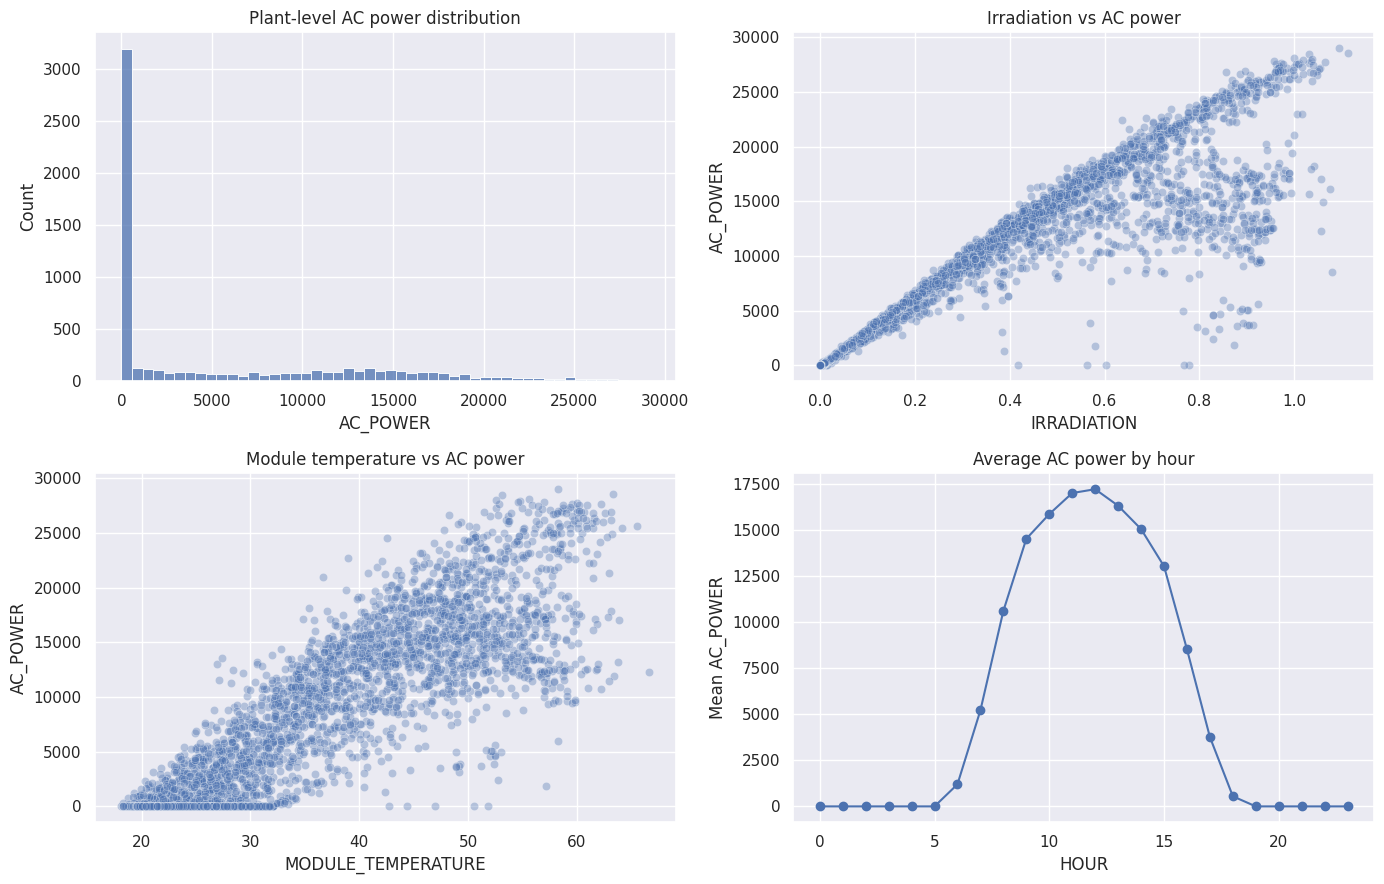

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(data=data, x="AC_POWER", bins=50, ax=axes[0,0])
axes[0,0].set_title("Plant-level AC power distribution")
sns.scatterplot(data=data.sample(min(5000, len(data)), random_state=42), x="IRRADIATION", y="AC_POWER", alpha=0.35, ax=axes[0,1])
axes[0,1].set_title("Irradiation vs AC power")
sns.scatterplot(data=data.sample(min(5000, len(data)), random_state=42), x="MODULE_TEMPERATURE", y="AC_POWER", alpha=0.35, ax=axes[1,0])
axes[1,0].set_title("Module temperature vs AC power")
hourly = data.assign(HOUR=data["DATE_TIME"].dt.hour).groupby("HOUR")["AC_POWER"].mean()
hourly.plot(ax=axes[1,1], marker="o")
axes[1,1].set_title("Average AC power by hour")
axes[1,1].set_ylabel("Mean AC_POWER")
plt.tight_layout()
plt.show()

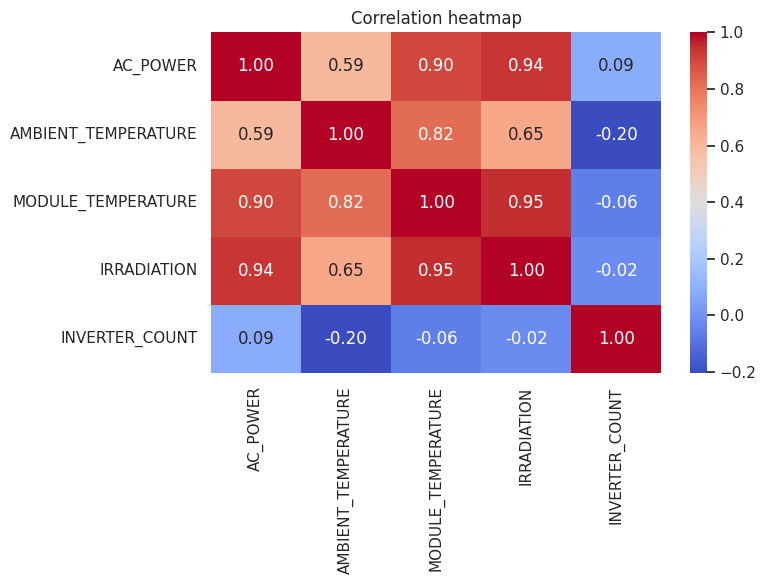

In [ ]:
corr_cols = ["AC_POWER", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION", "INVERTER_COUNT"]
plt.figure(figsize=(8, 6))
sns.heatmap(data[corr_cols].corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

## 7. Feature transformation and feature selection
Create time-based predictors from the timestamp. The primary model deliberately excludes direct generation variables (`DC_POWER`, daily yield and total yield) to reduce leakage. The chosen features are irradiation, temperatures, plant ID, hour, day of week and day of month. Humidity and wind are not present in this dataset, so they cannot be used without an additional data source.

In [ ]:
model_data = data.copy()
model_data["HOUR"] = model_data["DATE_TIME"].dt.hour
model_data["MINUTE"] = model_data["DATE_TIME"].dt.minute
model_data["DAY_OF_WEEK"] = model_data["DATE_TIME"].dt.dayofweek
model_data["DAY_OF_MONTH"] = model_data["DATE_TIME"].dt.day
model_data["MONTH"] = model_data["DATE_TIME"].dt.month

# Cyclical encodings preserve continuity around midnight and week boundaries.
model_data["HOUR_SIN"] = np.sin(2 * np.pi * model_data["HOUR"] / 24)
model_data["HOUR_COS"] = np.cos(2 * np.pi * model_data["HOUR"] / 24)
model_data["DOW_SIN"] = np.sin(2 * np.pi * model_data["DAY_OF_WEEK"] / 7)
model_data["DOW_COS"] = np.cos(2 * np.pi * model_data["DAY_OF_WEEK"] / 7)

feature_cols = [
    "PLANT_ID", "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE",
    "HOUR_SIN", "HOUR_COS", "DOW_SIN", "DOW_COS", "DAY_OF_MONTH", "MONTH"
]
target_col = "AC_POWER"

model_data = model_data.dropna(subset=[target_col]).sort_values("DATE_TIME").reset_index(drop=True)
X = model_data[feature_cols].copy()
y = model_data[target_col].astype(float).copy()

print("Predictors:", feature_cols)
print("Target:", target_col)
print("Rows available for modelling:", len(model_data))

Predictors: ['PLANT_ID', 'IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR_SIN', 'HOUR_COS', 'DOW_SIN', 'DOW_COS', 'DAY_OF_MONTH', 'MONTH']
Target: AC_POWER
Rows available for modelling: 6416


## 8. Temporal train/test partitioning
Because this is time-series-like data, use a chronological split instead of a random split. The latest 20% of timestamps are held out for testing, reducing the risk of training on future observations.

In [ ]:
unique_times = np.array(sorted(model_data["DATE_TIME"].dropna().unique()))
if len(unique_times) < 10:
    raise ValueError("Not enough unique timestamps for a reliable chronological split.")
cutoff_idx = int(len(unique_times) * 0.80)
cutoff_time = pd.Timestamp(unique_times[cutoff_idx])

train_mask = model_data["DATE_TIME"] < cutoff_time
test_mask = model_data["DATE_TIME"] >= cutoff_time

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

print("Cutoff timestamp:", cutoff_time)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train range:", model_data.loc[train_mask, "DATE_TIME"].min(), "to", model_data.loc[train_mask, "DATE_TIME"].max())
print("Test range:", model_data.loc[test_mask, "DATE_TIME"].min(), "to", model_data.loc[test_mask, "DATE_TIME"].max())

Cutoff timestamp: 2020-06-11 04:45:00
Train rows: 5112 | Test rows: 1304
Train range: 2020-05-15 00:00:00 to 2020-06-11 04:30:00
Test range: 2020-06-11 04:45:00 to 2020-06-17 23:45:00


## 9. Predictive model construction
Compare a simple Linear Regression baseline, Ridge Regression, and Random Forest Regression. Numerical values are imputed with the median; plant ID is one-hot encoded. Models are evaluated on the same chronological holdout.

In [ ]:
numeric_features = [c for c in feature_cols if c != "PLANT_ID"]
categorical_features = ["PLANT_ID"]

from sklearn.preprocessing import OneHotEncoder
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
])

model_specs = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1
    )
}
pipelines = {
    name: Pipeline([("preprocessor", preprocessor), ("regressor", model)])
    for name, model in model_specs.items()
}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(name, "training complete")

Linear Regression training complete
Ridge Regression training complete
Random Forest training complete


## 10. Evaluation
MAE and RMSE are in the same units as the aggregated `AC_POWER` target (sum of inverter AC power values per timestamp). R² describes the variance explained on the held-out period. Do not assume one model is best until you inspect the results.

In [ ]:
results = []
predictions = {}
for name, pipe in pipelines.items():
    pred = np.clip(pipe.predict(X_test), 0, None)  # power output cannot be negative
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })
results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(4))

,Model,MAE,RMSE,R2
2,Random Forest,470.9126,1321.8306,0.9628
0,Linear Regression,1428.5929,2170.7459,0.8998
1,Ridge Regression,1431.4509,2178.9978,0.8990


Model with lowest test RMSE: Random Forest


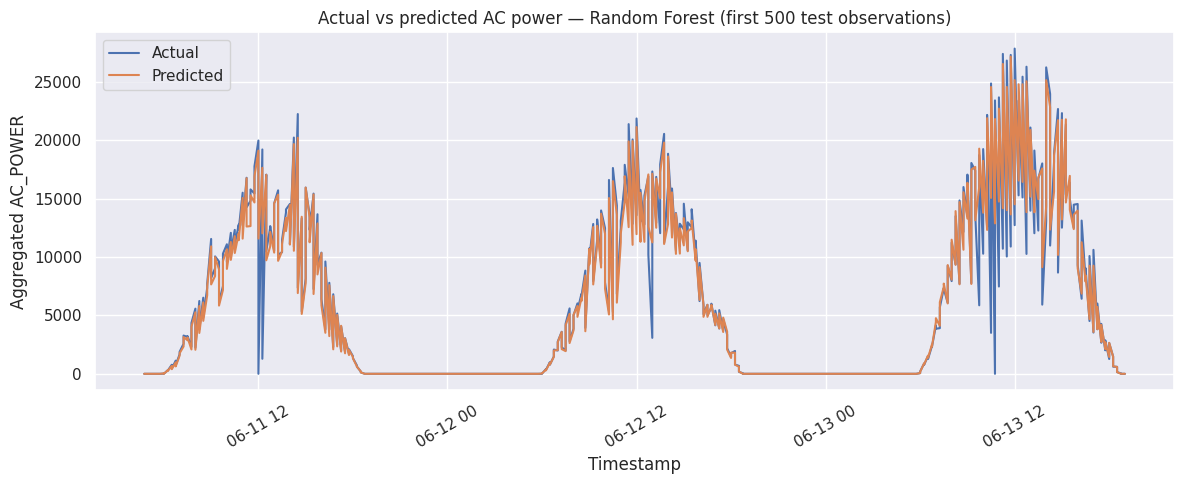

In [ ]:
best_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_name]
print("Model with lowest test RMSE:", best_name)

plt.figure(figsize=(12, 5))
n = min(500, len(y_test))
plt.plot(model_data.loc[test_mask, "DATE_TIME"].iloc[:n], y_test.iloc[:n].to_numpy(), label="Actual", linewidth=1.5)
plt.plot(model_data.loc[test_mask, "DATE_TIME"].iloc[:n], best_pred[:n], label="Predicted", linewidth=1.5)
plt.title(f"Actual vs predicted AC power — {best_name} (first {n} test observations)")
plt.xlabel("Timestamp")
plt.ylabel("Aggregated AC_POWER")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

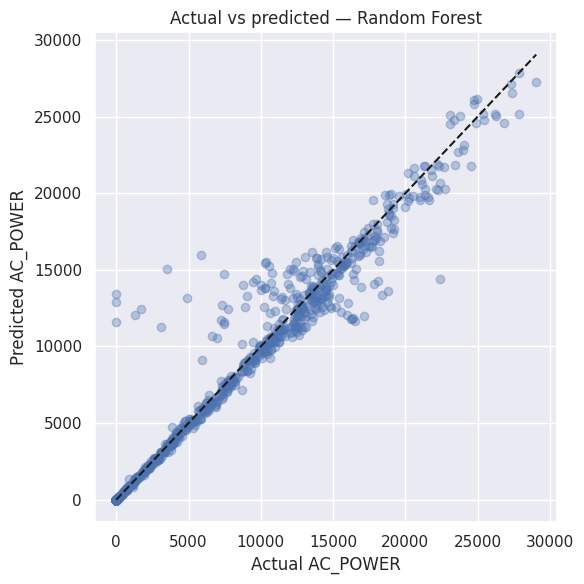

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.35)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
plt.plot(lims, lims, "k--")
plt.xlabel("Actual AC_POWER")
plt.ylabel("Predicted AC_POWER")
plt.title(f"Actual vs predicted — {best_name}")
plt.tight_layout()
plt.show()

## 11. Knowledge discovery and feature importance
Inspect Random Forest feature importance to understand which predictors the fitted model relied on most. Importance is model-specific and does not prove causation.

,importance
num__IRRADIATION,0.929659
cat__PLANT_ID_4136001,0.028410
cat__PLANT_ID_4135001,0.015175
num__DAY_OF_MONTH,0.008495
num__DOW_SIN,0.005322
num__MODULE_TEMPERATURE,0.004095
num__AMBIENT_TEMPERATURE,0.003359
num__HOUR_SIN,0.001652
num__DOW_COS,0.001639
num__HOUR_COS,0.001398


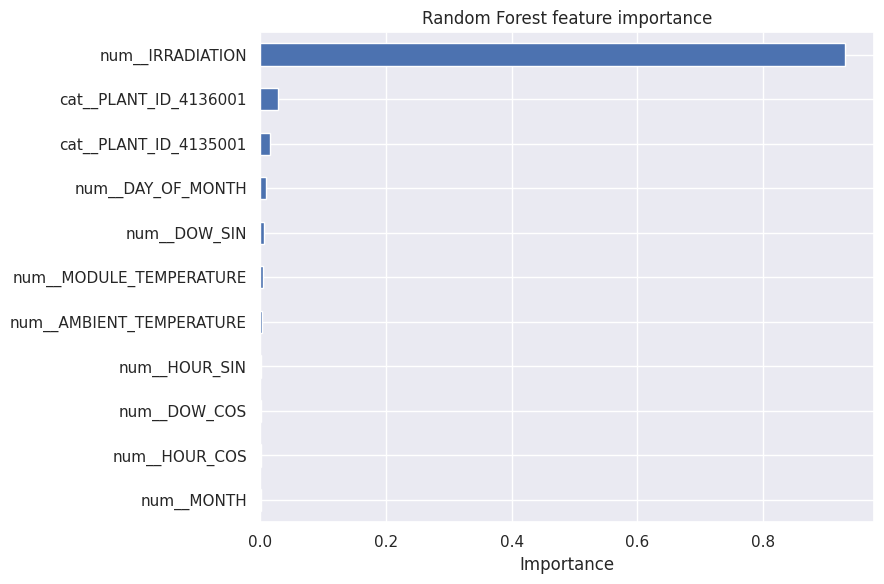

In [ ]:
rf_pipe = pipelines["Random Forest"]
pre = rf_pipe.named_steps["preprocessor"]
rf = rf_pipe.named_steps["regressor"]
try:
    names = pre.get_feature_names_out()
    importance = pd.Series(rf.feature_importances_, index=names).sort_values(ascending=False)
    display(importance.rename("importance").to_frame())
    importance.sort_values().plot(kind="barh", figsize=(9, 6))
    plt.title("Random Forest feature importance")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Could not create feature importance:", e)

## 12. Results and discussion

Model Performance: Random Forest achieved the best performance with a Test MAE of 470.91, RMSE of 1321.83, and R^2 of 0.9628, easily outperforming Linear and Ridge Regression (RMSE ~ 2170).
Time-Series Tracking: Predictions track the actual
daytime AC power curves very closely during peak generation hours, though sudden environmental fluctuations cause immediate volatility due to the lack of lagged features.
Irradiation Patterns: There is a strong, non-linear positive correlation between IRRADIATION and AC_POWER, with power dropping to zero at night and scaling upward with sunlight intensity.
Feature Importance: num__IRRADIATION heavily dominates the Random Forest model, accounting for roughly 92.97% of total feature importance, followed by plant IDs and temporal factors.

Practical Applications: Accurate forecasts enable grid operators to balance supply and demand dynamically and optimize energy storage system (ESS) charging/discharging cycles.

## 13. Conclusion
This notebook implements the KDD stages for solar power generation forecasting: data selection, preprocessing and integration, EDA, transformation, feature selection, chronological partitioning, regression modelling, evaluation and knowledge discovery. Complete the final conclusions using the metrics and charts produced by your run.

### Limitations
- The dataset covers only about 34 days and two plants, so it is not enough to validate year-round seasonal performance.
- The dataset has irradiation, ambient temperature and module temperature, but does not include humidity or wind speed in the listed sensor fields.
- This model estimates AC output using contemporaneous weather measurements. A true future forecast requires future weather forecasts or lagged features that are available at prediction time.
- `AC_POWER` is the sum of inverter AC power at a timestamp; the unit/scale should be described consistently with the dataset documentation.
- Feature importance shows model dependence, not causal influence.

## References
1. Ani Kannal, [Solar Power Generation Data — Kaggle](https://www.kaggle.com/datasets/anikannal/solar-power-generation-data)
2. [scikit-learn documentation](https://scikit-learn.org/stable/)
3. [Pandas documentation](https://pandas.pydata.org/docs/)